# Question 1: Research Papers - Expert System

Flow: load and denoise (1.1), choose columns and engineer features (1.2), baseline model and performance report (1.3).

In [1]:
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append('../deployment')
from text_utils import clean_text

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score)

## 1.1 Load the data frame and denoise the text

In [2]:
df = pd.DataFrame(json.load(open('../data/research_abstracts.json'))).reset_index(drop=True)
print(df.shape)
print(df.isna().sum())
print('Duplicate abstracts:', df['Abstract'].duplicated().sum())

# Duplicates are irrelevant information and could leak between the train and test sets, so remove them
df = df.drop_duplicates(subset='Abstract').reset_index(drop=True)
print('Rows after removing duplicates:', len(df))
df.head()

(1138, 3)
DOI         4
Abstract    0
Label       0
dtype: int64
Duplicate abstracts: 13
Rows after removing duplicates: 1125


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


**Denoising steps** (function `clean_text` in `deployment/text_utils.py`): lowercase; remove URLs, e-mail addresses and HTML tags; remove numbers and punctuation (keep letters only); remove English stop words; drop tokens of 1 to 2 letters.

In [3]:
df['clean'] = df['Abstract'].apply(clean_text)
for i in range(2):
    print('RAW  :', df['Abstract'][i][:300])
    print('CLEAN:', df['clean'][i][:300], '\n')

RAW  : Forward-looking forecasting of the inflation rate could help the central bank and other government departments to better use monetary policy to stabilize prices and prevent the impact of inflation on market entities, especially for low- and middle-income groups. It can also help financial institutio
CLEAN: forward looking forecasting inflation rate help central bank government departments better use monetary policy stabilize prices prevent impact inflation market entities especially low middle income groups help financial institutions investors better make investment decisions sense forecast inflation 

RAW  : Our study examined the disaggregation of inflation components in Nigeria using the stacked ensemble approach, a machine learning algorithm capable of compensating the weakness of an ensemble and a base learner with the strength of another. This approach gives flexibility of a synergistic performance
CLEAN: study examined disaggregation inflation components nigeria using st

       words_raw  words_clean
count     1125.0       1125.0
mean       171.6         98.7
std        103.9         59.0
min         16.0          9.0
25%        116.0         68.0
50%        152.0         89.0
75%        201.0        115.0
max       2075.0       1224.0
Empty after cleaning: 0


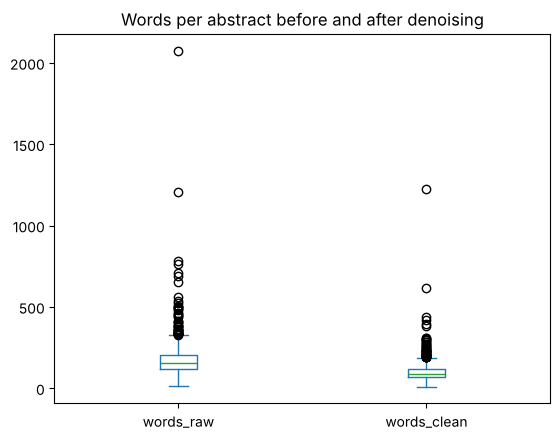

In [4]:
df['words_raw'] = df['Abstract'].str.split().str.len()
df['words_clean'] = df['clean'].str.split().str.len()
print(df[['words_raw', 'words_clean']].describe().round(1))
print('Empty after cleaning:', (df['words_clean'] == 0).sum())
df[['words_raw', 'words_clean']].plot(kind='box', title='Words per abstract before and after denoising')
plt.show()

In [5]:
# Save the cleaned data frame; Question 2 starts from this
df.to_csv('../data/abstracts_clean.csv', index=False)

## 1.2 Relevant columns and feature engineering

- `DOI`: an identifier (and 4 values are missing). It carries no meaning about the topic, so it is **dropped**.
- `Abstract` (cleaned as `clean`): the text the model learns from, so it is the **feature source**.
- `Label`: the **target** (`ai` or `classical`).

Feature engineering technique: **TF-IDF**. It turns each abstract into a vector in which a word's weight rises with how often it appears in that abstract and falls with how many abstracts contain it, so common filler words matter less.

Label
classical    890
ai           235
Name: count, dtype: int64


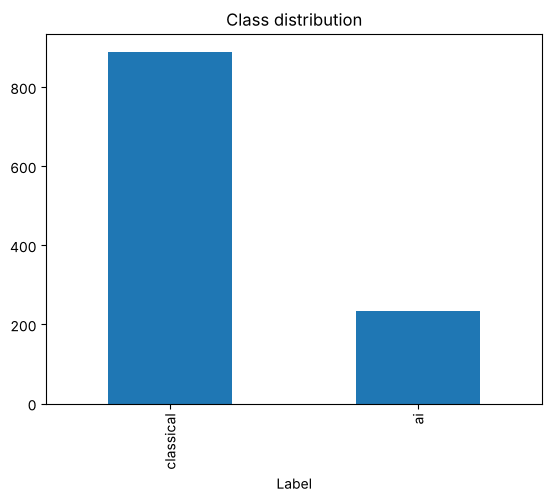

In [6]:
df['target'] = (df['Label'] == 'ai').astype(int)   # 1 = artificial intelligence, 0 = classical research
print(df['Label'].value_counts())
df['Label'].value_counts().plot(kind='bar', title='Class distribution')
plt.show()

Feature matrix: (1125, 5073)


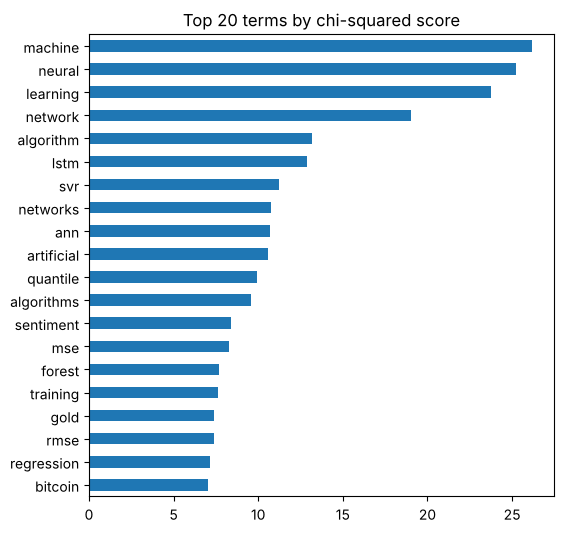

In [7]:
tfidf = TfidfVectorizer(min_df=2, sublinear_tf=True)
X_all = tfidf.fit_transform(df['clean'])
print('Feature matrix:', X_all.shape)

# Which terms are most associated with the AI label? (chi-squared score)
scores, _ = chi2(X_all, df['target'])
terms = np.array(tfidf.get_feature_names_out())
top = pd.Series(scores, index=terms).sort_values(ascending=False).head(20)
top.sort_values().plot(kind='barh', figsize=(6, 6), title='Top 20 terms by chi-squared score')
plt.show()

## 1.3 Baseline model

A stratified 80/20 train/test split (the same split is reused in Question 2). Baseline: **Multinomial Naive Bayes** on TF-IDF features, which is simple, fast and the standard starting point for text.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean'], df['target'], test_size=0.2, stratify=df['target'], random_state=42)
print('Train:', len(X_train), ' Test:', len(X_test))
print('Majority-class accuracy (always predict classical):', round(1 - y_test.mean(), 3))

Train: 900  Test: 225
Majority-class accuracy (always predict classical): 0.791


Train accuracy: 0.858
Test accuracy : 0.813



                         precision    recall  f1-score   support

     classical research       0.81      1.00      0.89       178
artificial intelligence       1.00      0.11      0.19        47

               accuracy                           0.81       225
              macro avg       0.90      0.55      0.54       225
           weighted avg       0.85      0.81      0.75       225



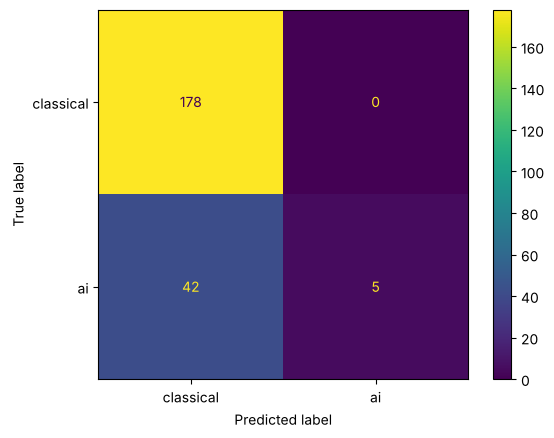

In [9]:
baseline = Pipeline([('tfidf', TfidfVectorizer(min_df=2, sublinear_tf=True)),
                     ('clf', MultinomialNB())])
baseline.fit(X_train, y_train)

train_pred = baseline.predict(X_train)
test_pred = baseline.predict(X_test)
print('Train accuracy:', round(accuracy_score(y_train, train_pred), 3))
print('Test accuracy :', round(accuracy_score(y_test, test_pred), 3))
print()
print(classification_report(y_test, test_pred, target_names=['classical research', 'artificial intelligence']))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=['classical', 'ai'])
plt.show()

### Learning and generalisation

The learning curve trains the baseline on growing portions of the training data and scores it with 5-fold cross-validation. It shows whether the model is still learning and whether it generalises.

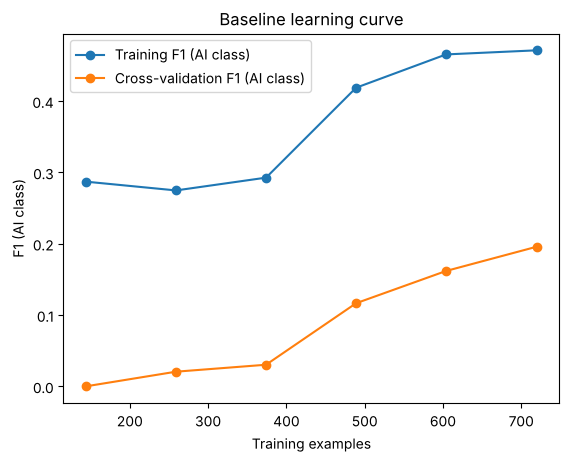

In [10]:
sizes, tr_scores, cv_scores = learning_curve(
    baseline, X_train, y_train, cv=5, scoring='f1',
    train_sizes=np.linspace(0.2, 1.0, 6), random_state=42)
plt.plot(sizes, tr_scores.mean(axis=1), marker='o', label='Training F1 (AI class)')
plt.plot(sizes, cv_scores.mean(axis=1), marker='o', label='Cross-validation F1 (AI class)')
plt.xlabel('Training examples'); plt.ylabel('F1 (AI class)')
plt.title('Baseline learning curve'); plt.legend(); plt.show()

### Comment on the baseline

- Accuracy looks acceptable (about 81% on the test set), but about 79% of the abstracts are classical research, so always predicting "classical" would score almost the same. Accuracy is misleading here.
- The classification report shows the real weakness: precision for the AI class is perfect but recall is only about 0.11, so the model finds roughly 1 in 10 AI abstracts (F1 for the AI class is about 0.19). Naive Bayes with plain priors favours the majority class.
- Train and test accuracy are close (about 86% vs 81%), so this is **underfitting / high bias**, not over-fitting: the model is too simple for the task rather than memorising the training data.
- The learning curve shows low scores on both the training and the validation data, so adding more data alone will not fix it. A model that weights the minority class and learns richer decision boundaries should do better. That is what Question 2 tests.